In [1]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
np.set_printoptions(legacy='1.21')

In [2]:
#Functions defined in previous classes

#Present values of a sum to be paid in n periods, discrete time
def pvdiscr(FV,r,n):
    return FV/((1+r)**n)

#Present values of a sum to be paid at T, continuous time
def pvcts(FV,r,T):
    return FV*np.exp(-r*T)

#Present values of a perpetuity with coupon C
def pvperp(C,r):
    return C/r

#Present value of paying C each period for N periods.
def pvann(C,r,N):
    return (C/r)*(1- (1/(1+r))**N)

#Alternative formula for an annuity.
def pvann2(C,r,N):
    p=[C/(1+r)**i for i in range(1,N+1)]
    return sum(p)

#Let r be the annual percentage rate (APR)
#Definition of Effective Annual Rate with k payments per year
def ear(r,k):
    y=(1+(r/k))**k-1
    return y

#Price of a bond
def bondprice(C,FV,r,N):
    return pvann2(C,r,N)+FV/(1+r)**N

#Annuity with less-than-annual payments
def pvannk(C,k,r,N):
    p=[(C/k)/(1+(ear(r,k)/k))**i for i in range(1,N*k+1)]
    return sum(p)

#The price of a bond when coupons are paid k times per year and r is APR
def bondpricek(C,k,FV,r,N):
    return pvannk(C,k,r,N)+FV/(1+(r/k))**(N*k)

#Forward value of an annuity
def fwann(C,r,N):
    return pvann2(C,r,N)*((1+r)**N)

#Alternative way to compute forward value.
def fwann2(C,r,N):
    p=[C*(1+r)**i for i in range(0,N)]
    return sum(p)

#Finding the YTM of a bond
def YTM(C,FV,N,P,guess):
    def equation1(x):
        return bondprice(C,FV,x,N) - P
    return fsolve(equation1,guess)

In [3]:
#Computing the duration of a bond
#(Macaulay) duration is the elasticity of the bond price to 1+YTM
def duration(C,FV,r,N):
    return sum(i*((C/((1+r)**i))/bondprice(C,FV,r,N)) for i in range(0,N))+N*(FV/(1+r)**N)/bondprice(C,FV,r,N)
duration(5,100,0.05,3)

2.729834791059281

In [4]:
for i in range(0,6):
    print(duration(2*i,100,0.05,3))

3.0
2.882319740369691
2.7778172453600924
2.6843964176092165
2.6003833253473885
2.524425014255845


In [5]:
for i in range(0,6):
    print(duration(3,100,0.01*i,3))

2.834862385321101
2.833618571037022
2.832366744457837
2.831106946199737
2.8298392170058375
2.828563597743417


In [6]:
#Duration when payments are less than annual.
def durationk(C, k, FV, r, N):
    price = bondpricek(C, k, FV, r, N)
    # Weighted present value of coupon payments
    pv_coupons = sum((i / k) * (C / k) / (1 + r / k) ** i for i in range(1, N * k + 1))
    # Weighted present value of principal repayment
    pv_fv = N * FV / (1 + r / k) ** (N * k)
    return (pv_coupons + pv_fv) / price

In [7]:
#Modified duration is duration/(1+YTM)
#It is useful because it measures how much a bond's price 
#will change in percentage terms when interest rates change by 1% (100 basis points)

def mod_duration(C, k, FV, r, N):
    D_mod = durationk(C, k, FV, r, N)/(1 + r/k)
    return D_mod

In [8]:
durationk(5, 2, 100, 0.03, 10)

8.172742676789067

In [9]:
mod_duration(5, 2, 100, 0.03, 10)

8.051963228363613

In [10]:
# Using duration to approximate price changes
# Delta P / P approximately equals -mod_duration * Delta y

initial_price = bondprice(5, 100, 0.05, 10)
new_yield = 0.057
delta_y = new_yield - 0.05
estimated_percentage_change = -mod_duration(5,1,100, 0.05, 10) * delta_y

estimated_price = initial_price * (
    1 + estimated_percentage_change)

print("Initial price:", initial_price)
print(
    "Estimated percentage price change:",
    estimated_percentage_change * 100,
    "%"
)
print("Estimated new price:", estimated_price)

Initial price: 99.99999999999997
Estimated percentage price change: -5.4052144504293675 %
Estimated new price: 94.59478554957062


In [11]:
# Compare duration approximation with actual price
actual_price = bondprice(5, 100, 0.057, 10)
actual_percentage_change = (actual_price - initial_price)/initial_price

print("Actual new price:", actual_price)
print("Actual percentage price change:",actual_percentage_change * 100,"%")
print("Difference between duration approximation and actual:", estimated_price - actual_price)

Actual new price: 94.77391314500268
Actual percentage price change: -5.226086854997293 %
Difference between duration approximation and actual: -0.1791275954320639


In [12]:
# Why duration is an approximation
yield_changes = np.linspace(-0.03, 0.03, 10000)

In [13]:
actual_prices = []
duration_prices = []
for dy in yield_changes:
    new_y = 0.05 + dy
    actual = bondprice(5, 100, new_y, 10)
    actual_prices.append(actual)
    duration_approx = initial_price * (1 - mod_duration(5,1,100, new_y, 10)* dy)
    duration_prices.append(duration_approx)

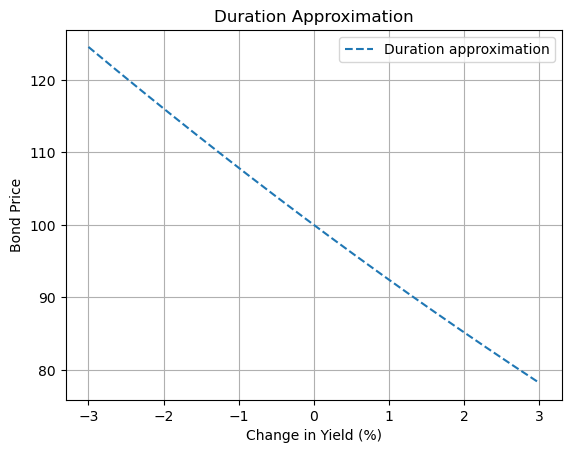

In [14]:
plt.plot(
    yield_changes * 100,
    duration_prices,
    '--',
    label='Duration approximation'
)
plt.xlabel('Change in Yield (%)')
plt.ylabel('Bond Price')
plt.title('Duration Approximation')
plt.legend()
plt.grid(True)
plt.show()


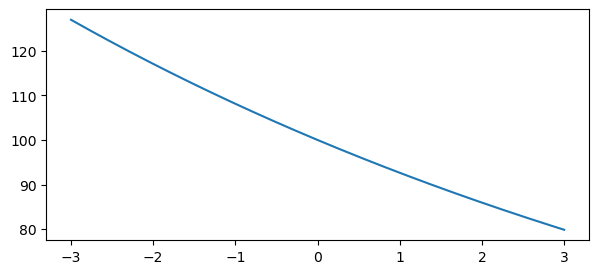

In [15]:
plt.figure(figsize=(7, 3))
plt.plot(
    yield_changes * 100,
    actual_prices,
    label='Actual bond price'
)